# Classificació de text amb Naive Bayes

Naive bayes és un model molt simple i com a tal, molt ràpid. Encara que els seus resultats no són perfectes, es pot utilitzar per a classificar textos molt ràpidament.

In [1]:
from sklearn.datasets import fetch_20newsgroups

data = fetch_20newsgroups()
data.target_names

['alt.atheism',
 'comp.graphics',
 'comp.os.ms-windows.misc',
 'comp.sys.ibm.pc.hardware',
 'comp.sys.mac.hardware',
 'comp.windows.x',
 'misc.forsale',
 'rec.autos',
 'rec.motorcycles',
 'rec.sport.baseball',
 'rec.sport.hockey',
 'sci.crypt',
 'sci.electronics',
 'sci.med',
 'sci.space',
 'soc.religion.christian',
 'talk.politics.guns',
 'talk.politics.mideast',
 'talk.politics.misc',
 'talk.religion.misc']

In [15]:
categories = ['talk.religion.misc', 'soc.religion.christian',
              'sci.space', 'comp.graphics']
train = fetch_20newsgroups(subset='train', categories=categories)
test = fetch_20newsgroups(subset='test', categories=categories)


print(train.data[7])
print("Numero de categoria: ",train.target[7])
print("Nom de la categoria: ",train.target_names[train.target[7]])

From: bprofane@netcom.com (Gert Niewahr)
Subject: Re: Rumours about 3DO ???
Article-I.D.: netcom.bprofaneC51wHz.HIo
Organization: Netcom Online Communications Services (408-241-9760 login: guest)
Lines: 39

In article <C51Eyz.4Ix@optimla.aimla.com> lex@optimla.aimla.com (Lex van Sonderen) writes:
>In article <h1p4s4g@zola.esd.sgi.com> erik@westworld.esd.sgi.com (Erik Fortune) writes:
>>> better than CDI
>>*Much* better than CDI.
>Of course, I do not agree.  It does have more horsepower.  Horsepower is not
>the only measurement for 'better'.  It does not have full motion, full screen
>video yet.  Does it have CD-ROM XA?
>
>>> starting in the 4 quarter of 1993
>>The first 3DO "multiplayer" will be manufactured by panasonic and will be 
>>available late this year.   A number of other manufacturers are reported to 
>>have 3DO compatible boxes in the works.
>Which other manufacturers?
>We shall see about the date.

A 3DO marketing rep. recently offered a Phillips marketing rep. a $100
bet t

Utilitzem un vectoritzador que ens dona Scikit-Learn. `TfidfVectorizer` crea una columna per a cada paraula (similar a un one-hot encoding paraula per paraula) i després utilitza la freqüència per informar de la importància ponderada d'aquesta paraula en tot el text. 

In [17]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

vectorizer = TfidfVectorizer()

model = make_pipeline(vectorizer, MultinomialNB())



In [21]:
vectorizer.fit(train.data)
print(vectorizer.transform([train.data[7]]))

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 180 stored elements and shape (1, 35329)>
  Coords	Values
  (0, 259)	0.04139926139804749
  (0, 1056)	0.026043925693455892
  (0, 1584)	0.053246646646580395
  (0, 1867)	0.04705401363482634
  (0, 2134)	0.04337069495799485
  (0, 2162)	0.4150757662982072
  (0, 2214)	0.04632962882519206
  (0, 2407)	0.07039726720394825
  (0, 3516)	0.0548434046544731
  (0, 4035)	0.05149718405560726
  (0, 4593)	0.035378078111162725
  (0, 4647)	0.196952691587123
  (0, 4795)	0.017493579132598434
  (0, 4877)	0.07303449136232726
  (0, 5020)	0.017609003797307368
  (0, 5063)	0.032555996540531824
  (0, 5152)	0.05107599883343264
  (0, 5507)	0.029735216335757122
  (0, 5627)	0.05019907996765121
  (0, 5823)	0.01660894637512198
  (0, 6038)	0.03310672378309766
  (0, 6277)	0.053246646646580395
  (0, 6412)	0.06792367969530201
  (0, 6450)	0.02432808728367636
  (0, 6483)	0.027639048006243488
  :	:
  (0, 31937)	0.022787617602099335
  (0, 31984)	0.05832489357744777
  (

* shape (1, 35329): Significa que la matriu té 1 sola fila (1 document analitzat) i 35.329 columnes (el diccionari total de paraules).

* with 180 stored elements: Tot i tenir un vocabulari de més de 35.000 paraules possibles, en aquest text concret només apareixen 180 paraules úniques (per això només es guarden aquests 180 elements i es salten tots els zeros).

In [22]:
model.fit(train.data, train.target)
labels = model.predict(test.data)

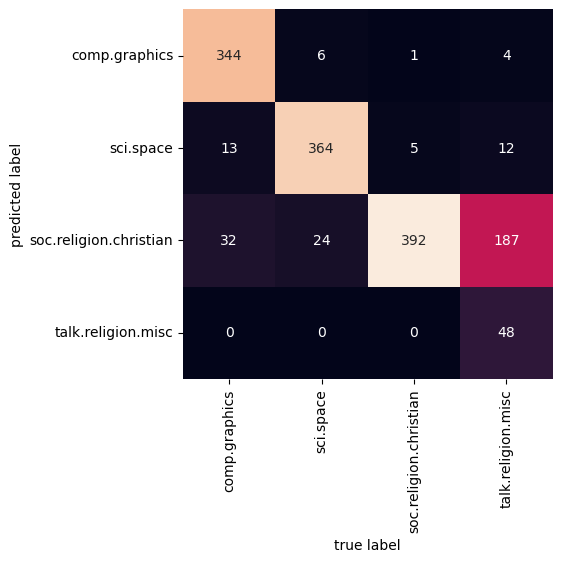

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(test.target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=train.target_names, yticklabels=train.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label');



> Interpreta els resultats

> Aconsegueix els textos de `comp.graphics` que el classificador els etiqueta com a `soc.religion.christian`. Imprimix un que et parega significatiu i interpreta perquè està mal etiquetat. Proposa millores. 